In [ ]:
import numpy as np
from base.iterative_section_minimiser import mesh_intersect
from stl import Mesh
import base.geometry as geom
import matplotlib.pyplot as plt
from tqdm import tqdm
from base.utils import find_neighbours_with_knn
from os.path import exists

In [2]:
mesh_data = Mesh.from_file(f"./data/EntranceGallery_extended_rotated.stl")

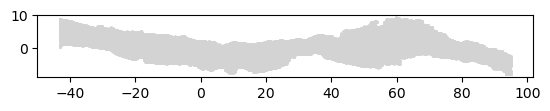

In [3]:
fig, ax = plt.subplots()

ax.scatter(*mesh_data.vectors[::100, 1, [0, 1]].T, s=1, color = "lightgrey")
ax.set_aspect("equal")

In [4]:
from base.LBC_centreline import return_LBC_centreline

In [ ]:
keep_centreline = True
adj_triangles_filepath = f"./data/EntranceGallery_extended_rotated_adjacent_triangles.txt"

if exists(adj_triangles_filepath) and keep_centreline == True:
    adj_triangles = np.loadtxt(adj_triangles_filepath)
else:
    adj_triangles = find_neighbours_with_knn(mesh_data)
    np.savetxt(adj_triangles_filepath, adj_triangles)

knn search complete and neighbouring triangles found in 625.0797s (4716744 triangle neighbour sets.)


In [14]:
LBC_result = return_LBC_centreline(f"./data/EntranceGallery_extended_rotated.stl", adj_triangles_filepath)

read file in 0.0000s


2025-04-30 13:39:28,753 - PCD #points: 18698


contracted file in 6.2501s


Volume ratio: 1.0. Contraction weights: 2048.0. Attraction weights: 5.600239028874076. Progress LBC:  15%|▏| 3/20 [00:02025-04-30 13:39:36,635 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 2048.0. Attraction weights: 5.600239028874076. Progress LBC:  15%|▏| 3/20 [00:0

Contraction is Done.
extracted skeleton in 7.9359s
downsampled the centreline cloud in 0.0040s
there were 0 connected components.
found largest component in 0.0010s
computed minimum spanning tree in 0.0051s
created graph instance of the centreline in  0.0000s
added node coordinates to graph in  0.0000s
found ring 1 with 1609 points.
found ring 2 with 957 points.


computed shortest path in  0.4273s


In [15]:
centreline = LBC_result["centreline"]

In [65]:
from base.refine_centreline import refine

In [67]:
centreline  = refine(centreline, 10)

In [68]:
vectors = centreline[1:] - centreline[:-1]
norm_vectors = np.linalg.norm(vectors, axis=1)
normed_vectors = vectors / np.expand_dims(norm_vectors, -1)

In [69]:
sections = [mesh_intersect(mesh_data, P, nP) for P, nP in tqdm(zip(centreline, normed_vectors), total= len(normed_vectors))]

100%|████████████████████████████████████████████████████████████████████████████████| 204/204 [04:35<00:00,  1.35s/it]


Plot the sections against the mesh vertices. 

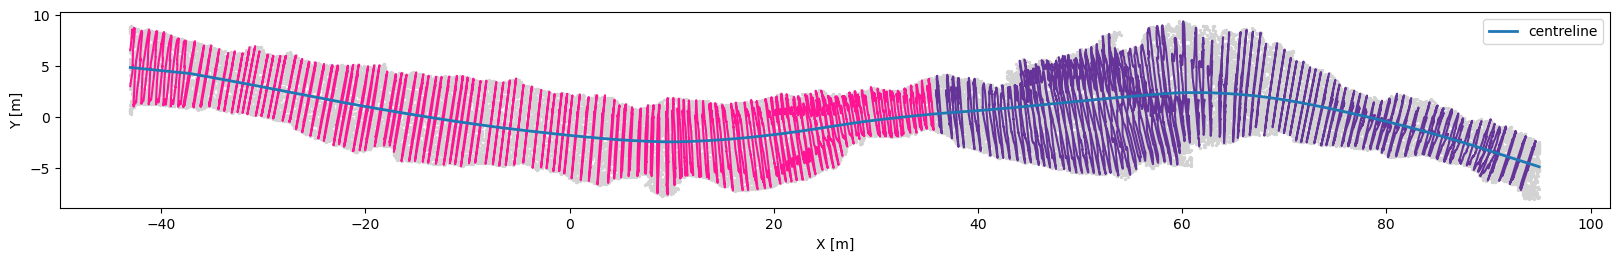

In [105]:
fig, ax = plt.subplots(figsize=(20, 10))

ax.scatter(*mesh_data[::100, [0,1]].T, color = "lightgrey", s = 2)

ax.plot(*centreline[:, [0,1]].T, zorder = 100, lw = 2, label = "centreline")
for section in sections[:117]:
    ax.plot(*section[0][:, [0,1]].T, color = "deeppink")


for section in sections[117:]:
    ax.plot(*section[0][:, [0,1]].T, color = "rebeccapurple")

ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

plt.savefig("./temp/FauxMonnayeurs_new_sections.pdf")

In [71]:
sections2d = [geom.to2D(elem[0], elem[5]) for elem in sections]

Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation unsuccessful
Rotation u

In [72]:
curvilinear_coords =np.hstack([np.zeros(1), np.cumsum(np.linalg.norm(vectors, axis =1))])

In [73]:
descriptors = []


for section, curvilinear_coord in tqdm(zip(sections2d, curvilinear_coords), total=len(sections2d)):
    cog = geom.centre_of_gravity(np.vstack([section.T, np.zeros(len(section))]).T)[:-1]
    area = geom.compute_ngon_area(section)
    perimeter = geom.compute_ngon_perimeter(section)
    max_length = geom.compute_max_pairwise_distance(section)
    
    rmax = geom.compute_rmax(section, cog)
    rmin = geom.compute_rmin(section, cog)
    r_average = geom.compute_rave(section, cog)
    solidity = geom.compute_polygon_solidity(section)

    determined_ellipse, ellipse_area, ellipse_perimeter, ellipse_aspect_ratio = geom.fit_ellipse(section)

    description = dict(
    xcord = curvilinear_coord, 
    cog = cog,
    area = area,
    ellipse_area= ellipse_area,
    ellipse_aspect_ratio = ellipse_aspect_ratio,
    perimeter = perimeter,
    solidity = solidity,
    hydraulic_diameter = geom.compute_ngon_dh(area, perimeter),
    max_length = max_length,
    rmax = rmax,
    rmin = rmin,
    r_average = r_average,
    circularity = rmin / rmax,
    circularity2 = perimeter **2 / area,
    gravelius_compactness = perimeter **2 / (2* np.sqrt(np.pi*area)),
    circularity3 = (rmax - rmin) / rmin,
    deviation_from_inscribe_disk = np.pi * rmin**2 / area,
    deviation_from_circumsribed_disk = np.pi * rmax**2 / area,
    elongation = 4 / np.pi *  (area / r_average**2),
    isoperimetric_deficiency = 4* np.pi * area / perimeter**2,
    morton_spreading_index = 4 / np.pi * (area / max_length**2),
    circular_variance = geom.compute_circular_variance(section, cog, area))

    descriptors.append(description)

100%|████████████████████████████████████████████████████████████████████████████████| 204/204 [00:06<00:00, 29.18it/s]


In [74]:
dhi = np.array([elem["hydraulic_diameter"] for elem in descriptors])

In [76]:
li = np.diff(curvilinear_coords)

In [80]:
def equivalent_dh(dhi, li):
    return np.sum(li)**(1/4) * np.sum(li *dhi**(-4))**(-1/4)

In [95]:
max_chords = np.array([elem["max_length"] for elem in descriptors])

117


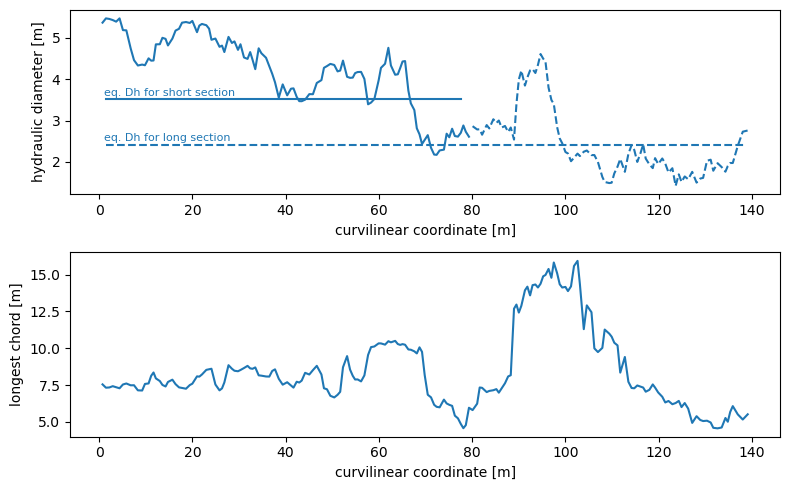

In [99]:
cond = curvilinear_coords[:-1] < 80
print(np.sum(cond))

fig, (ax, axchords) = plt.subplots(2, 1, figsize = (8, 5))

ax.plot(curvilinear_coords[:-1][cond][1:], dhi[cond][1:])
ax.plot(curvilinear_coords[:-1][~cond], dhi[~cond], ls = "--", color = "C0")


#plt.plot(curvilinear_coords[1:-1], [elem["hydraulic_diameter"] for elem in descriptors][1:], label = "hydraulic_diameter")
ax.axhline(equivalent_dh(dhi, li), ls = "--", xmin=0.05, xmax=0.95)
ax.axhline(equivalent_dh(dhi[:117], li[:117]), xmin=0.05, xmax=0.55)

ax.text(1,3.6, "eq. Dh for short section", color = "C0", fontsize = 8)
ax.text(1,2.5, "eq. Dh for long section", color = "C0", fontsize = 8)

ax.set_xlabel("curvilinear coordinate [m]")
ax.set_ylabel("hydraulic diameter [m]")


axchords.plot(curvilinear_coords[1:-1],max_chords[1:])
axchords.set_xlabel("curvilinear coordinate [m]")
axchords.set_ylabel("longest chord [m]")

plt.tight_layout()
plt.savefig("./temp/FauxMonnayeurs_hydraulic_diameters.pdf")

In [101]:
np.savetxt("./temp/FauxMonnayeurs_dimensions_curvilinear_no_header.txt", np.vstack([curvilinear_coords[1:-1], max_chords[1:], dhi[1:]]).T)

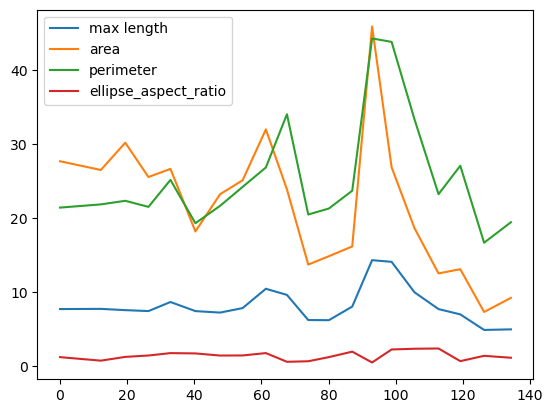

In [ ]:
plt.plot(curvilinear_coords[::10], [elem["max_length"] for elem in descriptors], label = "max length")
plt.plot(curvilinear_coords[::10], [elem["area"] for elem in descriptors], label = "area")
plt.plot(curvilinear_coords[::10], [elem["perimeter"] for elem in descriptors], label = "perimeter")

plt.legend()

In [9]:
from matplotlib.gridspec import GridSpec
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

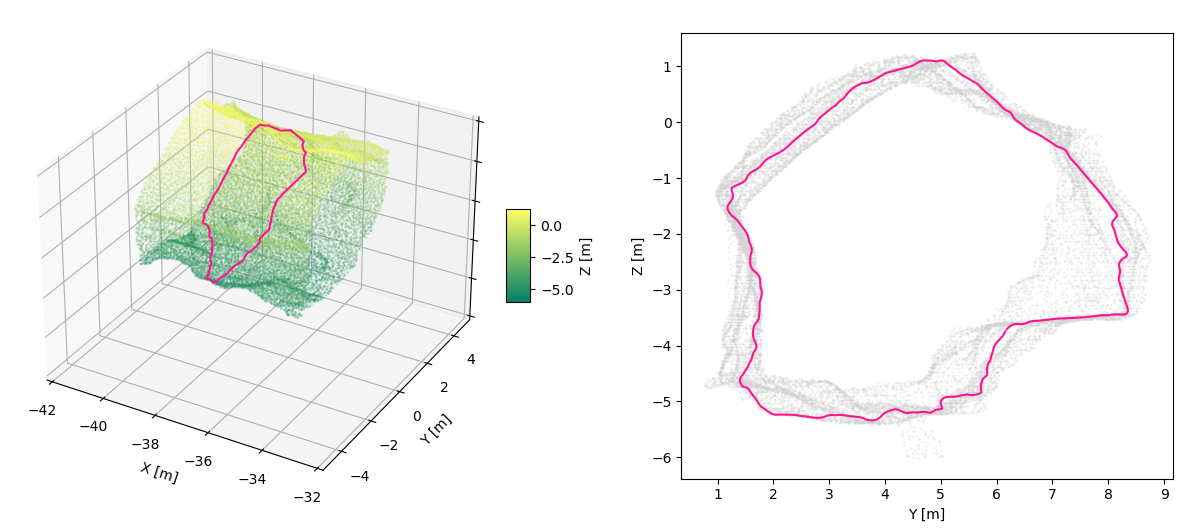

In [ ]:
fig = plt.figure(figsize = (15,7)) 
gs = GridSpec(nrows=5, ncols=40)

ax = fig.add_subplot(gs[:, :17], projection="3d")

cond = mesh_data.vectors[::10, 1, 0] < -36


minz, maxz = np.min(mesh_data.vectors[::10, 1, 2][cond]), np.max(mesh_data.vectors[::10, 1, 2][cond])

axcb = fig.add_subplot(gs[2:3, 17])

cb = plt.colorbar(ScalarMappable(norm=Normalize(minz, maxz), cmap='summer'),
             cax=axcb, orientation='vertical', label='Z [m]')

ax.scatter(*mesh_data.vectors[::10, 1, [0, 1, 2]][cond].T, s=1, c = mesh_data.vectors[::10, 1, 2][cond],  cmap = "summer", zorder = -100, alpha = 0.2)
ax.plot(*section[0][:, [0, 1, 2]].T,  color = "deeppink", zorder = 10000)

ax.set_xlim(-42, -32)
ax.set_xlabel("X [m]")
ax.set_ylim(-5, 5)
ax.set_xlim(-42, -32)
ax.set_ylabel("Y [m]")
ax.set_zlim(-6, 4)
ax.set_zticklabels([])

ax = fig.add_subplot(gs[:, 23:])
ax.scatter(*mesh_data.vectors[::10, 1, [1, 2]][cond].T, s=1, color = "lightgrey", zorder = -100, alpha = 0.2)
ax.plot(*section[0][:, [ 1, 2]].T,  color = "deeppink", zorder = 10000)
ax.set_aspect("equal")
ax.set_xlabel("Y [m]")
ax.set_ylabel("Z [m]")
plt.savefig("./temp/An example_section.pdf")
plt.show()

In [29]:
vertices2d = section[0][:, [1, 2]]

In [30]:
vertices2d

array([[ 6.15515566, -3.74749374],
       [ 6.14121771, -3.77248764],
       [ 6.13889265, -3.77713132],
       ...,
       [ 6.2018199 , -3.68692899],
       [ 6.19944239, -3.68977571],
       [ 6.182374  , -3.70926476]])

In [31]:
import polylabel

In [32]:
vertices2d

array([[ 6.15515566, -3.74749374],
       [ 6.14121771, -3.77248764],
       [ 6.13889265, -3.77713132],
       ...,
       [ 6.2018199 , -3.68692899],
       [ 6.19944239, -3.68977571],
       [ 6.182374  , -3.70926476]])

In [33]:
cog = geom.centre_of_gravity(np.vstack([vertices2d.T, np.zeros(len(vertices2d))]).T)[:-1]
area = geom.compute_ngon_area(vertices2d)
perimeter = geom.compute_ngon_perimeter(vertices2d)
max_length = geom.compute_max_pairwise_distance(vertices2d)
rmax = geom.compute_rmax(vertices2d, cog)
rmin = geom.compute_rmin(vertices2d, cog)
r_average = geom.compute_rave(vertices2d, cog)
solidity = geom.compute_polygon_solidity(vertices2d)
convexhull = geom.compute_convex_hull(vertices2d)
hydraulic_diameter = geom.compute_ngon_dh(area, perimeter)

determined_ellipse, ellipse_area, ellipse_perimeter, ellipse_aspect_ratio = geom.fit_ellipse(vertices2d, verbose = True)

description = dict(
cog = cog,
area = area,
ellipse_area= ellipse_area,
ellipse_aspect_ratio = ellipse_aspect_ratio,
perimeter = perimeter,
solidity = solidity,
hydraulic_diameter = geom.compute_ngon_dh(area, perimeter),
max_length = max_length,
rmax = rmax,
rmin = rmin,
r_average = r_average,
circularity = rmin / rmax,
circularity2 = perimeter **2 / area,
gravelius_compactness = perimeter **2 / (2* np.sqrt(np.pi*area)),
circularity3 = (rmax - rmin) / rmin,
deviation_from_inscribe_disk = np.pi * rmin**2 / area,
deviation_from_circumsribed_disk = np.pi * rmax**2 / area,
elongation = 4 / np.pi *  (area / r_average**2),
isoperimetric_deficiency = 4* np.pi * area / perimeter**2,
morton_spreading_index = 4 / np.pi * (area / max_length**2),
circular_variance = geom.compute_circular_variance(vertices2d, cog, area))


[-0.05907318  0.00985745] 31.162973675672333
[239.01985425 175.19302103] [[ 0.94680963 -0.32179424]
 [ 0.32179424  0.94680963]]
1.168042345713661


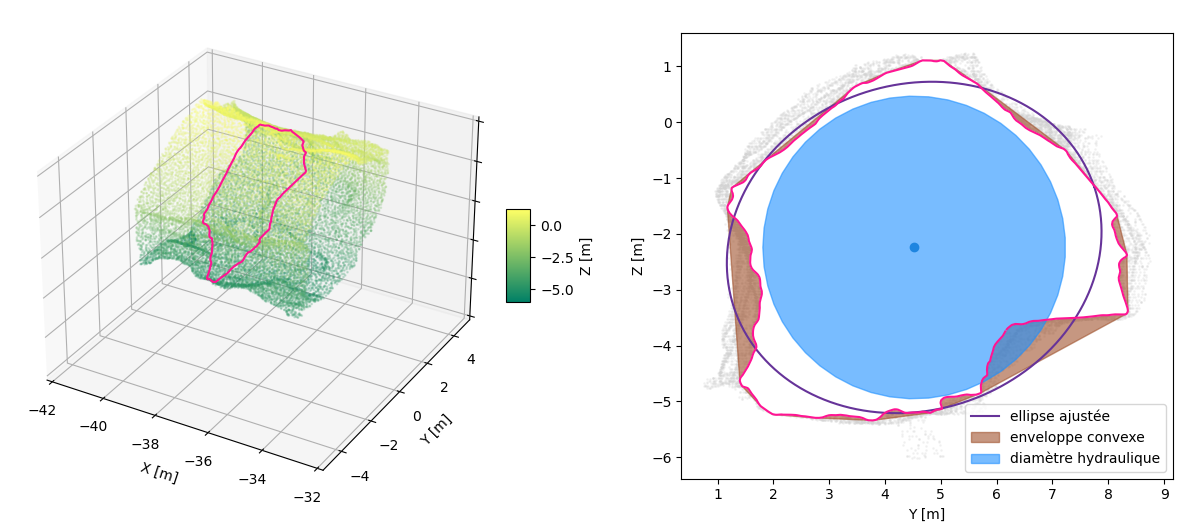

In [34]:
fig = plt.figure(figsize = (15,7)) 
gs = GridSpec(nrows=5, ncols=40)

ax = fig.add_subplot(gs[:, :17], projection="3d")

cond = mesh_data.vectors[::10, 1, 0] < -36


minz, maxz = np.min(mesh_data.vectors[::10, 1, 2][cond]), np.max(mesh_data.vectors[::10, 1, 2][cond])

axcb = fig.add_subplot(gs[2:3, 17])

cb = plt.colorbar(ScalarMappable(norm=Normalize(minz, maxz), cmap='summer'),
             cax=axcb, orientation='vertical', label='Z [m]')

ax.scatter(*mesh_data.vectors[::10, 1, [0, 1, 2]][cond].T, s=1, c = mesh_data.vectors[::10, 1, 2][cond],  cmap = cm, zorder = -100, alpha = 0.2)
ax.plot(*section[0][:, [0, 1, 2]].T,  color = "deeppink", zorder = 10000)

ax.set_xlim(-42, -32)
ax.set_xlabel("X [m]")
ax.set_ylim(-5, 5)
ax.set_xlim(-42, -32)
ax.set_ylabel("Y [m]")
ax.set_zlim(-6, 4)
ax.set_zticklabels([])

## this is a section view. 

# now add all the geometric descriptors. 

ax = fig.add_subplot(gs[:, 23:])
ax.scatter(*mesh_data.vectors[::10, 1, [1, 2]][cond].T, s=1, color = "lightgrey", zorder = -100, alpha = 0.2)
ax.plot(*section[0][:, [ 1, 2]].T,  color = "deeppink", zorder = 10000)
ax.fill(*section[0][:, [ 1, 2]].T,  color = "white", zorder = -10)

ax.set_aspect("equal")
ax.set_xlabel("Y [m]")
ax.set_ylabel("Z [m]")

## do the ellipse thing. 
thetai = np.linspace(-np.pi, np.pi)

ax.plot(*determined_ellipse.T, color = "rebeccapurple", label = "ellipse ajustée")
ax.scatter(*cog)
ax.fill(*convexhull.T, color = "sienna", alpha = 0.6, zorder = -11, label = "enveloppe convexe")
ax.fill(cog[0]+np.cos(thetai)*hydraulic_diameter/2, cog[1]+np.sin(thetai)*hydraulic_diameter/2, color = "dodgerblue", alpha = 0.6, zorder = 11, label = "diamètre hydraulique")

ax.legend(loc = "lower right")
plt.savefig("./temp/An example_section_with descriptors.pdf")
plt.show()

In [35]:
# work out the transforms for the 
original_mesh_data = Mesh.from_file("./data/EntranceGallery.stl")

In [ ]:
T1 = np.mean(original_mesh_data.centroids[:, [0, 1]], axis = 0)

In [91]:
meanz = np.mean(original_mesh_data.centroids[:, 2])

In [66]:
X1 = original_mesh_data.centroids[:, [0, 1]] - T1
X2 =mesh_data.centroids[:, [0, 1]]

In [67]:
Cov1 = X1.T @ X1
eigenvalues1, eigenvectors1 = np.linalg.eig(Cov1)
Cov2 = X2.T @ X2
eigenvalues2, eigenvectors2 = np.linalg.eig(Cov2)

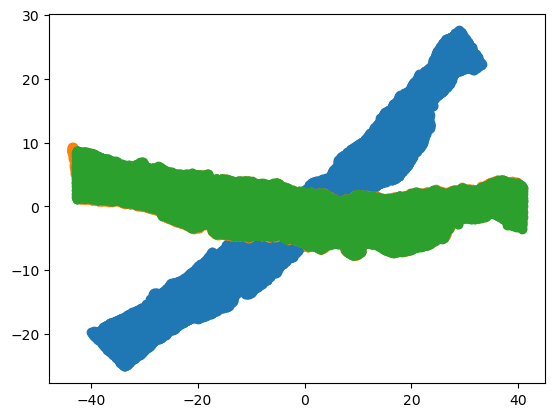

In [ ]:
fig, ax = plt.subplots()

Xprime2 = X1 @ eigenvectors1 @ eigenvectors2.T

ax.scatter(*X1[::100].T)
ax.scatter(*Xprime2[::100].T)
ax.scatter(*X2[::100].T)

In [ ]:
ROTATION  = eigenvectors1 @ eigenvectors2.T
TRANSLATION = T1

In [77]:
# work out the transforms for the 
extended_mesh_data = Mesh.from_file("./data/EntranceGallery_extended.stl")

In [78]:
X3 = extended_mesh_data.centroids[:, [0, 1]] - T1


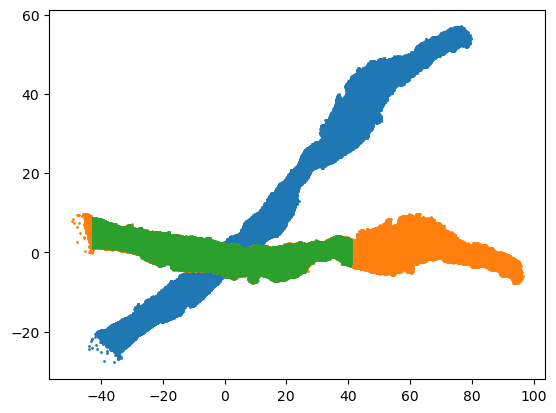

In [80]:
fig, ax = plt.subplots()
Xprime3 = X3 @ eigenvectors1 @ eigenvectors2.T

ax.scatter(*X3[::100].T, s = 1)
ax.scatter(*Xprime3[::100].T, s= 1)
ax.scatter(*X2[::100].T, s =1)

In [83]:
ntriangles, nverts, ncoords = extended_mesh_data.vectors.shape

In [85]:
rot = np.zeros((3, 3))
rot[:2,:2] = eigenvectors1 @ eigenvectors2.T
rot[2,2] = 1

In [92]:
extended_mesh_vectors_flat = (extended_mesh_data.vectors.reshape((ntriangles * nverts), ncoords) - np.array([*T1, meanz])) @ rot

In [93]:
extended_mesh_vectors = extended_mesh_vectors_flat.reshape((ntriangles, nverts, ncoords))

In [94]:
extended_mesh_vectors[0]

array([[-43.48159877,   4.64300052,  -4.30819702],
       [-43.47250063,   4.61007132,  -4.35818481],
       [-43.47606813,   4.60554398,  -4.30819702]])

In [95]:
extended_mesh_data.vectors[0]

array([[225.33847  ,   2.6519966, 441.60596  ],
       [225.366    ,   2.6317635, 441.55597  ],
       [225.366    ,   2.6259995, 441.60596  ]], dtype=float32)

In [96]:
extended_mesh_surface = Mesh(np.zeros(ntriangles, dtype=Mesh.dtype))
extended_mesh_surface.vectors = extended_mesh_vectors

In [97]:
extended_mesh_surface.save("./data/EntranceGallery_extended_rotated.stl")